In [35]:
import random
import numpy as np
import torch

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

# Usage
set_seed(42)

In [ ]:
%load_ext autoreload
%autoreload 2
from lcb_no_forget import LCB, LCBModel
import os
from nets import ValueEstimate, LogUBaselineNet, train_val_estimate, load_val_estimate
from collection import Collector
run_id = "20260122_202321_157606"
run_dir = os.path.join("toy_data_runs", run_id)
alpha = 0.2

value_estimator_temp_0p2, states, index_set, _ = load_val_estimate(run_id, 0.2, device="mps")
value_estimator_temp_0p33, states, index_set, _ = load_val_estimate(run_id, 0.33, device="mps")
value_estimator_temp_1p0, states, index_set, _ = load_val_estimate(run_id, 1.0, device="mps")
collector = Collector(None, None)
core, states, expr = collector.load_collected(run_dir)
core.S = 7000
print("states shape:", states.shape)
in_dim = value_estimator_temp_0p2.in_dim

In [ ]:
lcb = LCB(
    2, 
    value_estimator_temp_0p2,
    core,
    delta = 0.1,
    fix_lambda=True,
    symmetric= True,
    lambda_value=1,
    lam_min=1,
    lam_max=2,
    erm_error=0.0,
    baseline_lr = 1e-4
)

model_temp_0p2 = LCBModel(core, lcb)
model_temp_0p2.num_train_steps_per_t = 200
model_temp_0p2.num_baseline_epochs_per_step = 1
X = model_temp_0p2.train()

print("effective N = ", model_temp_0p2.num_steps/(7000*20))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
states shape: (20, 70000, 2)
LCB Model has S =  7000


KeyboardInterrupt: 

In [ ]:
lcb.save(run_dir, run_id, alpha, name = "lambda_fixed_1_source")

{'ckpt': 'toy_data_runs/20260122_202321_157606/lambda_fixed_1_source_20260122_202321_157606_lcb_temp_0p2_SYM.pt'}

In [ ]:
model_temp_0p2_delta_0p005 = model_temp_0p2
model_temp_0p2_delta_0p005.lcb.lam_max = 20
model_temp_0p2_delta_0p005.lcb.fix_lambda = False
model_temp_0p2_delta_0p005.lcb.delta = 0.005

model_temp_0p2_delta_0p005.num_train_steps_per_t = 1
model_temp_0p2_delta_0p005.num_steps = 0
X_temp_0p2_delta_0p005 = model_temp_0p2_delta_0p005.train()
print("effective N (delta=0.005) = ", model_temp_0p2_delta_0p005.num_steps/(7000*20))

model_temp_0p2_delta_0p05 = model_temp_0p2
model_temp_0p2_delta_0p05.lcb.lam_max = 10
model_temp_0p2_delta_0p05.lcb.fix_lambda = False
model_temp_0p2_delta_0p05.lcb.delta = 0.05

model_temp_0p2_delta_0p05.num_train_steps_per_t = 1
model_temp_0p2_delta_0p05.num_steps = 0
X_temp_0p2_delta_0p05 = model_temp_0p2_delta_0p05.train()
print("effective N (delta=0.05) = ", model_temp_0p2_delta_0p05.num_steps/(7000*20))

model_temp_0p2_delta_0p1 = model_temp_0p2
model_temp_0p2_delta_0p1.lcb.lam_max = 10
model_temp_0p2_delta_0p1.lcb.delta = 0.1
model_temp_0p2_delta_0p1.num_steps = 0
model_temp_0p2_delta_0p1.lcb.fix_lambda = False
model_temp_0p2_delta_0p1.num_train_steps_per_t = 1
X_temp_0p2_delta_0p1 = model_temp_0p2_delta_0p1.train()
print("effective N (delta=0.1) = ", model_temp_0p2_delta_0p1.num_steps/(7000*20))

model_temp_0p2_delta_0p2 = model_temp_0p2
model_temp_0p2_delta_0p2.lcb.lam_max = 10
model_temp_0p2_delta_0p2.lcb.fix_lambda = False
model_temp_0p2_delta_0p2.lcb.delta = 0.2

model_temp_0p2_delta_0p2.num_train_steps_per_t = 1
model_temp_0p2_delta_0p2.num_steps = 0
X_temp_0p2_delta_0p2 = model_temp_0p2_delta_0p2.train()
print("effective N (delta=0.2) = ", model_temp_0p2_delta_0p2.num_steps/(7000*20))

model_temp_0p2_delta_0p3 = model_temp_0p2
model_temp_0p2_delta_0p3.lcb.lam_max = 10
model_temp_0p2_delta_0p3.lcb.fix_lambda = False
model_temp_0p2_delta_0p3.lcb.delta = 0.3

model_temp_0p2_delta_0p3.num_train_steps_per_t = 1
model_temp_0p2_delta_0p3.num_steps = 0
X_temp_0p2_delta_0p3 = model_temp_0p2_delta_0p3.train()
print("effective N (delta=0.3) = ", model_temp_0p2_delta_0p3.num_steps/(7000*20))



effective N (delta=0.005) =  9.394607142857144
effective N (delta=0.05) =  7.0780642857142855
effective N (delta=0.1) =  5.863614285714286
effective N (delta=0.2) =  4.425971428571429
effective N (delta=0.3) =  3.4241285714285716


In [ ]:
model_temp_0p2_delta_0p005.lcb.save(run_dir, run_id, alpha, name = "temp_0p2_delta_0p005")
model_temp_0p2_delta_0p05.lcb.save(run_dir, run_id, alpha, name = "temp_0p2_delta_0p05")
model_temp_0p2_delta_0p1.lcb.save(run_dir, run_id, alpha, name = "temp_0p2_delta_0p1")
model_temp_0p2_delta_0p2.lcb.save(run_dir, run_id, alpha, name = "temp_0p2_delta_0p2")
model_temp_0p2_delta_0p3.lcb.save(run_dir, run_id, alpha, name = "temp_0p2_delta_0p3")

{'ckpt': 'toy_data_runs/20260122_202321_157606/temp_0p2_delta_0p3_20260122_202321_157606_lcb_temp_0p2_SYM.pt'}

In [ ]:
import matplotlib.pyplot as plt
plt.hist(X_rs[0, :, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p2_delta_0p005[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p2_delta_0p05[:, 0], bins = 100, density=True, alpha=0.5)
plt.hist(X_temp_0p2_delta_0p1[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p2_delta_0p2[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p2_delta_0p3[:, 0], bins = 100, density=True, alpha=0.5)
plt.show()

In [ ]:
%load_ext autoreload
%autoreload 2
from lcb_no_forget import LCB, LCBModel
import os
from nets import ValueEstimate, LogUBaselineNet, train_val_estimate, load_val_estimate
from collection import Collector
run_id = "20260122_202321_157606"
run_dir = os.path.join("toy_data_runs", run_id)
alpha = 0.33

set_seed(42)

value_estimator, states, index_set, _ = load_val_estimate(run_id, alpha, device="mps")
collector = Collector(None, None)
core, states, expr = collector.load_collected(run_dir)


core.S = 7000
print("states shape:", states.shape)
in_dim = value_estimator.in_dim

# Train LCB ################
    

lcb = LCB(
    2, 
    value_estimator_temp_0p33,
    core,
    delta = 0.1,
    fix_lambda=True,
    symmetric= True,
    lambda_value=1,
    lam_min=1,
    lam_max=2,
    erm_error=0.0,
    baseline_lr = 1e-4
)

model_temp_0p33 = LCBModel(core, lcb)
model_temp_0p33.num_train_steps_per_t = 200
model_temp_0p33.num_baseline_epochs_per_step = 1
X = model_temp_0p33.train()

print("effective N = ", model_temp_0p33.num_steps/(7000*20))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
states shape: (20, 70000, 2)
LCB Model has S =  7000
effective N =  9.332885714285714


In [53]:
lcb.save(run_dir, run_id, alpha, name = "lambda_fixed_1_temp_0p33")

{'ckpt': 'toy_data_runs/20260122_202321_157606/lambda_fixed_1_temp_0p33_20260122_202321_157606_lcb_temp_0p2_SYM.pt'}

In [ ]:
model_temp_0p33_delta_0p005 = model_temp_0p33
model_temp_0p33_delta_0p005.lcb.lam_max = 20
model_temp_0p33_delta_0p005.lcb.fix_lambda = False
model_temp_0p33_delta_0p005.lcb.delta = 0.005

model_temp_0p33_delta_0p005.num_train_steps_per_t = 1
model_temp_0p33_delta_0p005.num_steps = 0
X_temp_0p33_delta_0p005 = model_temp_0p33_delta_0p005.train()
print("effective N (temp=0.33, delta=0.005) = ", model_temp_0p33_delta_0p005.num_steps/(7000*20))

model_temp_0p33_delta_0p05 = model_temp_0p33
model_temp_0p33_delta_0p05.lcb.lam_max = 10
model_temp_0p33_delta_0p05.lcb.fix_lambda = False
model_temp_0p33_delta_0p05.lcb.delta = 0.05

model_temp_0p33_delta_0p05.num_train_steps_per_t = 1
model_temp_0p33_delta_0p05.num_steps = 0
X_temp_0p33_delta_0p05 = model_temp_0p33_delta_0p05.train()
print("effective N (temp=0.33, delta=0.05) = ", model_temp_0p33_delta_0p05.num_steps/(7000*20))

model_temp_0p33_delta_0p1 = model_temp_0p33
model_temp_0p33_delta_0p1.lcb.lam_max = 10
model_temp_0p33_delta_0p1.lcb.delta = 0.1
model_temp_0p33_delta_0p1.num_steps = 0
model_temp_0p33_delta_0p1.lcb.fix_lambda = False
model_temp_0p33_delta_0p1.num_train_steps_per_t = 1
X_temp_0p33_delta_0p1 = model_temp_0p33_delta_0p1.train()
print("effective N (temp=0.33, delta=0.1) = ", model_temp_0p33_delta_0p1.num_steps/(7000*20))

model_temp_0p33_delta_0p2 = model_temp_0p33
model_temp_0p33_delta_0p2.lcb.lam_max = 10
model_temp_0p33_delta_0p2.lcb.fix_lambda = False
model_temp_0p33_delta_0p2.lcb.delta = 0.2

model_temp_0p33_delta_0p2.num_train_steps_per_t = 1
model_temp_0p33_delta_0p2.num_steps = 0
X_temp_0p33_delta_0p2 = model_temp_0p33_delta_0p2.train()
print("effective N (temp=0.33, delta=0.2) = ", model_temp_0p33_delta_0p2.num_steps/(7000*20))

model_temp_0p33_delta_0p3 = model_temp_0p33
model_temp_0p33_delta_0p3.lcb.lam_max = 10
model_temp_0p33_delta_0p3.lcb.fix_lambda = False
model_temp_0p33_delta_0p3.lcb.delta = 0.3

model_temp_0p33_delta_0p3.num_train_steps_per_t = 1
model_temp_0p33_delta_0p3.num_steps = 0
X_temp_0p33_delta_0p3 = model_temp_0p33_delta_0p3.train()
print("effective N (temp=0.33, delta=0.3) = ", model_temp_0p33_delta_0p3.num_steps/(7000*20))

effective N (temp=0.33, delta=0.005) =  3.9489714285714284
effective N (temp=0.33, delta=0.05) =  2.4952
effective N (temp=0.33, delta=0.1) =  2.1261714285714284
effective N (temp=0.33, delta=0.2) =  1.8138
effective N (temp=0.33, delta=0.3) =  1.6895714285714285


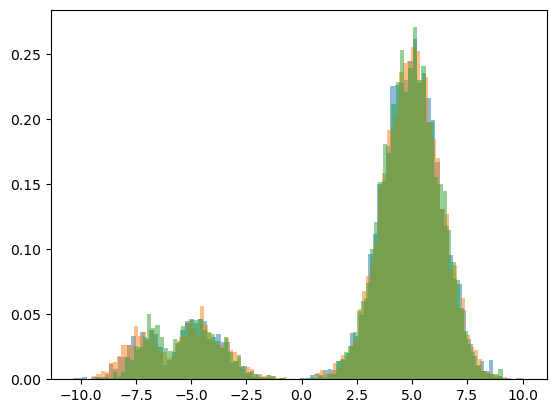

In [52]:
import matplotlib.pyplot as plt
plt.hist(X_rs_temp_0p33[0, :, 0], bins = 100, density=True, alpha=0.5)
plt.hist(X_temp_0p33_delta_0p005[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p33_delta_0p05[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p33_delta_0p1[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p33_delta_0p2[:, 0], bins = 100, density=True, alpha=0.5)
plt.hist(X_temp_0p33_delta_0p3[:, 0], bins = 100, density=True, alpha=0.5)
plt.show()

In [54]:
lcb = LCB(
    2, 
    value_estimator_temp_1p0,
    core,
    delta = 0.1,
    fix_lambda=True,
    symmetric= True,
    lambda_value=1,
    lam_min=1,
    lam_max=2,
    erm_error=0.0,
    baseline_lr = 1e-4
)

model_temp_1p0 = LCBModel(core, lcb)
model_temp_1p0.num_train_steps_per_t = 200
model_temp_1p0.num_baseline_epochs_per_step = 1
X = model_temp_1p0.train()

lcb.save(run_dir, run_id, alpha, name = "lambda_fixed_1_temp_1p0")

print("effective N = ", model_temp_1p0.num_steps/(7000*20))

model_temp_1p0_delta_0p005 = model_temp_1p0
model_temp_1p0_delta_0p005.lcb.lam_max = 20
model_temp_1p0_delta_0p005.lcb.fix_lambda = False
model_temp_1p0_delta_0p005.lcb.delta = 0.005

model_temp_1p0_delta_0p005.num_train_steps_per_t = 1
model_temp_1p0_delta_0p005.num_steps = 0
X_temp_1p0_delta_0p005 = model_temp_1p0_delta_0p005.train()
print("effective N (temp=1.0, delta=0.005) = ", model_temp_1p0_delta_0p005.num_steps/(7000*20))

model_temp_1p0_delta_0p05 = model_temp_1p0
model_temp_1p0_delta_0p05.lcb.lam_max = 10
model_temp_1p0_delta_0p05.lcb.fix_lambda = False
model_temp_1p0_delta_0p05.lcb.delta = 0.05

model_temp_1p0_delta_0p05.num_train_steps_per_t = 1
model_temp_1p0_delta_0p05.num_steps = 0
X_temp_1p0_delta_0p05 = model_temp_1p0_delta_0p05.train()
print("effective N (temp=1.0, delta=0.05) = ", model_temp_1p0_delta_0p05.num_steps/(7000*20))

model_temp_1p0_delta_0p1 = model_temp_1p0
model_temp_1p0_delta_0p1.lcb.lam_max = 10
model_temp_1p0_delta_0p1.lcb.delta = 0.1
model_temp_1p0_delta_0p1.num_steps = 0
model_temp_1p0_delta_0p1.lcb.fix_lambda = False
model_temp_1p0_delta_0p1.num_train_steps_per_t = 1
X_temp_1p0_delta_0p1 = model_temp_1p0_delta_0p1.train()
print("effective N (temp=1.0, delta=0.1) = ", model_temp_1p0_delta_0p1.num_steps/(7000*20))

model_temp_1p0_delta_0p2 = model_temp_1p0
model_temp_1p0_delta_0p2.lcb.lam_max = 10
model_temp_1p0_delta_0p2.lcb.fix_lambda = False
model_temp_1p0_delta_0p2.lcb.delta = 0.2

model_temp_1p0_delta_0p2.num_train_steps_per_t = 1
model_temp_1p0_delta_0p2.num_steps = 0
X_temp_1p0_delta_0p2 = model_temp_1p0_delta_0p2.train()
print("effective N (temp=1.0, delta=0.2) = ", model_temp_1p0_delta_0p2.num_steps/(7000*20))

model_temp_1p0_delta_0p3 = model_temp_1p0
model_temp_1p0_delta_0p3.lcb.lam_max = 10
model_temp_1p0_delta_0p3.lcb.fix_lambda = False
model_temp_1p0_delta_0p3.lcb.delta = 0.3

model_temp_1p0_delta_0p3.num_train_steps_per_t = 1
model_temp_1p0_delta_0p3.num_steps = 0
X_temp_1p0_delta_0p3 = model_temp_1p0_delta_0p3.train()
print("effective N (temp=1.0, delta=0.3) = ", model_temp_1p0_delta_0p3.num_steps/(7000*20))

LCB Model has S =  7000
effective N =  9.011714285714286
effective N (temp=1.0, delta=0.005) =  1.1767785714285715
effective N (temp=1.0, delta=0.05) =  1.21765
effective N (temp=1.0, delta=0.1) =  1.1359785714285715
effective N (temp=1.0, delta=0.2) =  1.0585714285714285
effective N (temp=1.0, delta=0.3) =  1.01475


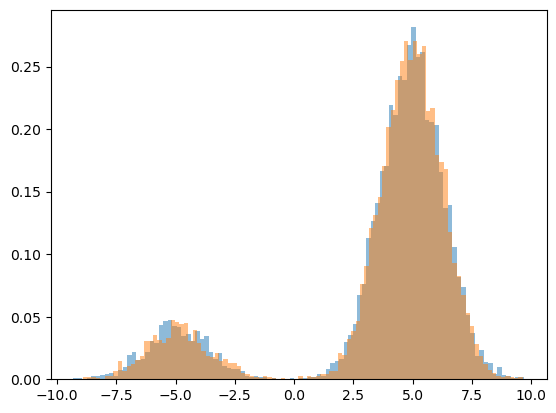

In [58]:
import matplotlib.pyplot as plt
plt.hist(X_rs_temp_1p0[0, :, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_1p0_delta_0p005[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p33_delta_0p05[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p33_delta_0p1[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p33_delta_0p2[:, 0], bins = 100, density=True, alpha=0.5)
plt.hist(X_temp_1p0_delta_0p3[:, 0], bins = 100, density=True, alpha=0.5)
plt.show()

In [ ]:
from animate_2d import animate_val_predictions
alpha_str = str(alpha).replace(".", "p")
animate_val_predictions(states, index_set, lcb, outfile=f"{run_dir}/lcb_{alpha_str}_SYM.gif")


Predictions shape: (20, 2500)
Value prediction range: -13.815511 0.41842315


'toy_data_runs/20260122_202321_157606/lcb_0p2_SYM.gif'

In [44]:
import numpy as np

class RejectionSampling:
    """
    Simple rejection sampling policy analogous to LCBModel.lcb_step, but with
    acceptance probability:   p_accept = exp(v_t(x_t) - B)

    where v_t is provided in *log-space* by value_estimator.predict_under_log(...),
    and B is a user-chosen constant (typically >= max log v so p<=1 mostly).
    """
    def __init__(self, core, value_estimator, B: float, N: int = 5):
        self.core = core
        self.core.reset()
        self.value_estimator = value_estimator
        self.index_set = self.core.model_config["index_set"]
        self.B = float(B)
        self.N = int(N)

        self.S = self.core.S
        self.num_steps = 0  # total proposals used (like LCBModel.num_steps)

    def rs_step(self):
        """
        Perform one reverse-time step (t+1 -> t) using rejection sampling.
        Mirrors LCBModel.lcb_step structure.

        Returns:
            accepted_states: (S, d) np.ndarray
            num_proposals:   length-S list[int] proposals consumed per chain
        """
        tp1 = self.core.t  # current time index is "t+1" in their convention
        if tp1 < 0:
            raise ValueError(f"rs_step called with core.t={tp1}; expected t>=1 (so we can go to t-1).")

        Xtp1 = self.core.X  # (S, d)
        S = Xtp1.shape[0]

        # proposals per active chain per loop-iteration
        self.core.N = self.N

        active = list(range(S))
        accepted_states = [None] * S
        num_proposals = [0] * S

        # Loop until every chain accepts a proposal
        while active:
            # Propose candidates for currently-active indices.
            # Expected shape: (N, len(active), d)
            Xt = self.core.propose_external(Xtp1[active], tp1, N=self.core.N)

            # log v_t for each proposed state at time t = tp1-1
            # expected shape: (N, len(active))
            logvt = self.value_estimator.predict_under_log(Xt, self.index_set[tp1 - 1])

            acc = np.exp(logvt - self.B)
            acc = np.clip(acc, 0.0, 1.0)

            u = np.random.rand(*acc.shape)

            # Ensure acc is shaped (A, N): rows = active chains, cols = proposals
            # A = len(active), N = self.core.N
            A = len(active)
            N = self.core.N
            if acc.shape == (N, A):
                acc = acc.T
                u = u.T
            elif acc.shape != (A, N):
                raise ValueError(f"Unexpected acc shape {acc.shape}; expected {(A, N)} or {(N, A)}")

            new_active = []
            for j, orig_idx in enumerate(active):
                ok = np.where(acc[j, :] > u[j, :])[0]
                if ok.size:
                    first = int(ok[0])
                    # Xt could be (N, A, d) or (A, N, d) depending on Core; handle both.
                    if Xt.shape[:2] == (N, A):
                        accepted_states[orig_idx] = Xt[first, j]
                    elif Xt.shape[:2] == (A, N):
                        accepted_states[orig_idx] = Xt[j, first]
                    else:
                        raise ValueError(f"Unexpected Xt shape {Xt.shape}; expected {(N, A, 'd')} or {(A, N, 'd')}")
                    num_proposals[orig_idx] += first + 1
                else:
                    new_active.append(orig_idx)
                    num_proposals[orig_idx] += N

            active = new_active


        accepted_states = np.stack(accepted_states, axis=0)
        self.core.commit(accepted_states)
        self.num_steps += int(sum(num_proposals))
        return accepted_states, num_proposals

    def set_S(self, S: int):
        self.core.S = int(S)
        self.S = int(S)
        self.core.reset()

    def calc_samples(self):
        """
        Roll out samples using rejection sampling, returning an array of shape (T+1, S, d),
        matching LCBModel.calc_samples().
        """
        self.core.reset()
        self.num_steps = 0

        # initial noisy state at time T
        init_props = self.core.propose()
        if init_props.ndim == 3:
            x_init = init_props[:, 0, :]
        else:
            x_init = init_props
        self.core.commit(x_init)

        T_plus_1 = self.core.T + 1
        d = x_init.shape[-1]
        states = np.empty((T_plus_1, self.S, d))
        states[self.core.t + 1] = x_init  # time index T

        while self.core.t >= 0:
            states_t, _ = self.rs_step()
            states[self.core.t] = states_t

        return states


# ---------------------------------------------------------------------
# Example usage (mirrors how you use LCBModel)
# ---------------------------------------------------------------------
# rs = RejectionSampling(core=core, value_estimator=value_estimator, B=YOUR_B, N=5)
# rs.core.S = 5000
# rs.set_S(5000)
# states = rs.calc_samples()
# print("num proposals:", rs.num_steps)


rs_temp_0p2 = RejectionSampling(core=core, value_estimator=value_estimator_temp_0p2, B=1/0.2)
rs_temp_0p33 = RejectionSampling(core=core, value_estimator=value_estimator_temp_0p33, B=1/0.33)
rs_temp_1p0 = RejectionSampling(core=core, value_estimator=value_estimator_temp_1p0, B=1)

rs_temp_0p2.set_S(7000)
rs_temp_0p33.set_S(7000)
rs_temp_1p0.set_S(7000)

X_rs_temp_0p2 = rs_temp_0p2.calc_samples()
X_rs_temp_0p33 = rs_temp_0p33.calc_samples()
X_rs_temp_1p0 = rs_temp_1p0.calc_samples()
print("proposal per timestep ratio (temp = 0.2)", rs_temp_0p2.num_steps/(7000*20))
print("proposal per timestep ratio (temp = 0.33)", rs_temp_0p33.num_steps/(7000*20))
print("proposal per timestep ratio (temp = 1.0)", rs_temp_1p0.num_steps/(7000*20))


proposal per timestep ratio (temp = 0.2) 63.80502142857143
proposal per timestep ratio (temp = 0.33) 13.759592857142858
proposal per timestep ratio (temp = 1.0) 1.951007142857143


In [59]:
import pickle
import os

# Define the data structure to save all samples and effective N values
data = {
    'temp_0.2': {
        'rs_samples': X_rs_temp_0p2,
        'rs_effective_N': rs_temp_0p2.num_steps / (7000 * 20),
        'lcb_delta_0.005': {
            'samples': X_temp_0p2_delta_0p005,
            'effective_N': model_temp_0p2_delta_0p005.num_steps / (7000 * 20)
        },
        'lcb_delta_0.05': {
            'samples': X_temp_0p2_delta_0p05,
            'effective_N': model_temp_0p2_delta_0p05.num_steps / (7000 * 20)
        },
        'lcb_delta_0.1': {
            'samples': X_temp_0p2_delta_0p1,
            'effective_N': model_temp_0p2_delta_0p1.num_steps / (7000 * 20)
        },
        'lcb_delta_0.2': {
            'samples': X_temp_0p2_delta_0p2,
            'effective_N': model_temp_0p2_delta_0p2.num_steps / (7000 * 20)
        },
        'lcb_delta_0.3': {
            'samples': X_temp_0p2_delta_0p3,
            'effective_N': model_temp_0p2_delta_0p3.num_steps / (7000 * 20)
        }
    },
    'temp_0.33': {
        'rs_samples': X_rs_temp_0p33,
        'rs_effective_N': rs_temp_0p33.num_steps / (7000 * 20),
        'lcb_delta_0.005': {
            'samples': X_temp_0p33_delta_0p005,
            'effective_N': model_temp_0p33_delta_0p005.num_steps / (7000 * 20)
        },
        'lcb_delta_0.05': {
            'samples': X_temp_0p33_delta_0p05,
            'effective_N': model_temp_0p33_delta_0p05.num_steps / (7000 * 20)
        },
        'lcb_delta_0.1': {
            'samples': X_temp_0p33_delta_0p1,
            'effective_N': model_temp_0p33_delta_0p1.num_steps / (7000 * 20)
        },
        'lcb_delta_0.2': {
            'samples': X_temp_0p33_delta_0p2,
            'effective_N': model_temp_0p33_delta_0p2.num_steps / (7000 * 20)
        },
        'lcb_delta_0.3': {
            'samples': X_temp_0p33_delta_0p3,
            'effective_N': model_temp_0p33_delta_0p3.num_steps / (7000 * 20)
        }
    },
    'temp_1.0': {
        'rs_samples': X_rs_temp_1p0,
        'rs_effective_N': rs_temp_1p0.num_steps / (7000 * 20),
        'lcb_delta_0.005': {
            'samples': X_temp_1p0_delta_0p005,
            'effective_N': model_temp_1p0_delta_0p005.num_steps / (7000 * 20)
        },
        'lcb_delta_0.05': {
            'samples': X_temp_1p0_delta_0p05,
            'effective_N': model_temp_1p0_delta_0p05.num_steps / (7000 * 20)
        },
        'lcb_delta_0.1': {
            'samples': X_temp_1p0_delta_0p1,
            'effective_N': model_temp_1p0_delta_0p1.num_steps / (7000 * 20)
        },
        'lcb_delta_0.2': {
            'samples': X_temp_1p0_delta_0p2,
            'effective_N': model_temp_1p0_delta_0p2.num_steps / (7000 * 20)
        },
        'lcb_delta_0.3': {
            'samples': X_temp_1p0_delta_0p3,
            'effective_N': model_temp_1p0_delta_0p3.num_steps / (7000 * 20)
        }
    }
}

# Save the data to a pickle file in the run directory
output_file = os.path.join(run_dir, 'lcb_and_rs_results.pkl')
with open(output_file, 'wb') as f:
    pickle.dump(data, f)

print(f"All results saved to {output_file}")

All results saved to toy_data_runs/20260122_202321_157606/lcb_and_rs_results.pkl


In [70]:
X_unguided_N[0, :, :].reshape(S, N, 2).shape

(7000, 3, 2)

In [ ]:
# from mixture_lower import Mixture
def reward_func_hard(x):
    x0 = np.asarray(x)[..., 0]
    return np.where(x0 < -7, 1, 0)
# # Best-of-N
# mu_0 = np.array([[5, 0], [-5, 0]])
# var_0 = np.eye(d)
# pi_0 = np.array([0.95, 0.05])
# pi_0 /= np.sum(pi_0)
# dist0 = Mixture(mu_0, var_0, pi_0)
S = 7000
BoN_Ns = [10]
# BoN_Ns = [60, 70]
# BoN_sets = {}
for N in BoN_Ns:
    print("N = ", N)
    core.S = N*S
    X_unguided_N= core.collect_run()
    X_N_candidates = X_unguided_N[0, :, :].reshape(S, N, 2)
    rewards = (reward_func_hard(X_N_candidates))
    best_indices = np.argmax(rewards, axis=1)
    X_best = X_N_candidates[np.arange(S), best_indices, :]
    BoN_sets[N] = (X_best)
# unguided_num_steps = 


N =  10


(array([0.0013739 , 0.00274781, 0.        , 0.00274781, 0.00274781,
        0.00618257, 0.00961733, 0.014426  , 0.02335638, 0.04053018,
        0.05495618, 0.07144304, 0.12021665, 0.14563388, 0.18204236,
        0.21776387, 0.23562463, 0.24455501, 0.18753797, 0.12571227,
        0.06938218, 0.01373905, 0.01305209, 0.02816504, 0.03846933,
        0.04533885, 0.05014752, 0.06113875, 0.05358228, 0.0590779 ,
        0.06526047, 0.04808666, 0.04396495, 0.03366066, 0.04396495,
        0.03228676, 0.02335638, 0.01992162, 0.01099124, 0.01373905,
        0.00686952, 0.00480867, 0.00274781, 0.0013739 , 0.00068695,
        0.        , 0.0013739 , 0.0013739 , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.00068695,
        0.00068695, 0.00412171, 0.0013739 , 0.00068695, 0.00343476,
        0.00824343, 0.00480867, 0.01167819, 0.01717381, 0.02060857,
        0.02953895, 0.03159981, 0.04739971, 0.05289533, 0.07281694,
        0.0906777 , 0.11334713, 0.1209036 , 0.12

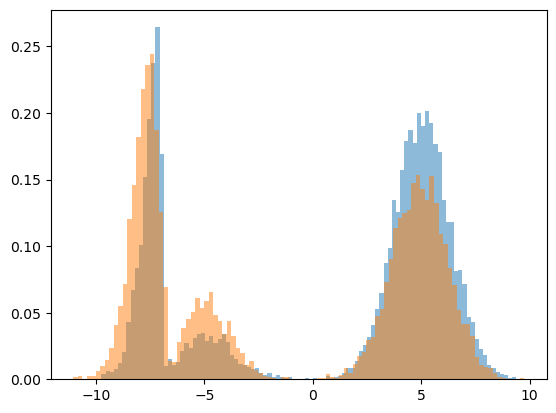

In [ ]:
plt.hist(BoN_sets[10][:, 0], bins = 100, density=True, alpha=0.5)
plt.hist(X_rs_temp_0p33[0, :, 0], bins = 100, density=True, alpha=0.5)